# Entrega 02: Análise de Regressão dos Dados

Na entrega anterior nós olhamos para a distribuição de cada indicador financeiro separadamente: média, mediana, dispersão, outliers. Agora o objetivo é entender como os indicadores se relacionam entre si. Para isso vamos ajustar um modelo de regressão linear, interpretar o que os coeficientes dizem, verificar se o ajuste é bom e registrar as limitações que encontramos pelo caminho.

A base usada é a mesma da entrega anterior, já tratada e normalizada: `Demonstrativo_Normalizado.csv`, com 14.400 linhas (1.200 cenários simulados por Monte Carlo, ao longo de 12 anos de concessão) e os indicadores financeiros organizados em colunas.

Ao longo do notebook cada termo técnico é explicado na primeira vez que aparece, e no final há um glossário com todos eles reunidos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['text.color'] = 'black'
plt.rcParams['axes.labelcolor'] = 'black'
plt.rcParams['xtick.color'] = 'black'
plt.rcParams['ytick.color'] = 'black'

pd.set_option('display.width', 150)
pd.set_option('display.max_columns', 20)

BI = 1e9  # os valores estao em reais, nos graficos mostramos em bilhoes de reais

In [2]:
df = pd.read_csv('Demonstrativo_Normalizado.csv', sep=';', decimal=',', encoding='utf-8-sig')
df['Ano'] = df['Ano'].astype(int)
df['Cenario'] = df['Cenario'].astype(int)

print('Linhas e colunas:', df.shape)
df[['Ano', 'Cenario', 'DRE - Receita', 'DRE - EBITDA', 'DRE - Resultado Líquido',
    'FLU - Geração de Caixa', 'FLU - Saldo Final', 'BAL - Total do Ativo']].head()

Linhas e colunas: (14400, 71)


,Ano,Cenario,DRE - Receita,DRE - EBITDA,DRE - Resultado Líquido,FLU - Geração de Caixa,FLU - Saldo Final,BAL - Total do Ativo
0,1,1,6.722729e+09,5.188381e+09,2.443243e+09,4.306498e+08,1.205265e+09,1.063113e+10
1,1,2,6.703608e+09,5.172388e+09,2.436562e+09,4.243157e+08,1.198931e+09,1.062391e+10
2,1,3,6.676361e+09,5.149189e+09,2.434790e+09,4.211763e+08,1.195792e+09,1.062317e+10
3,1,4,6.672623e+09,5.146146e+09,2.435385e+09,4.216127e+08,1.196228e+09,1.062329e+10
4,1,5,6.660653e+09,5.136879e+09,2.416009e+09,4.052842e+08,1.179899e+09,1.060179e+10


## 1. Escolhendo as variáveis do modelo

Antes de sair ajustando uma regressão qualquer, vale a pena olhar como os indicadores se correlacionam entre si. Isso evita um erro comum: montar um modelo que parece ótimo só porque as variáveis escolhidas são, na prática, quase a mesma coisa escrita de formas diferentes.

A medida usada é o coeficiente de correlação de Pearson. Ele varia de -1 a +1: perto de +1 as duas variáveis sobem juntas, perto de -1 uma sobe quando a outra desce, e perto de 0 não há relação linear.

In [3]:
indicadores = ['Ano', 'Cenario', 'DRE - Receita', 'DRE - EBITDA', 'DRE - Resultado Líquido',
               'FLU - Geração de Caixa', 'FLU - Saldo Final', 'BAL - Total do Ativo']

corr = df[indicadores].corr(numeric_only=True).round(3)
corr

,Ano,Cenario,DRE - Receita,DRE - EBITDA,DRE - Resultado Líquido,FLU - Geração de Caixa,FLU - Saldo Final,BAL - Total do Ativo
Ano,1.000,0.000,0.913,0.874,0.878,-0.172,0.276,-0.852
Cenario,0.000,1.000,-0.008,-0.005,-0.027,0.019,-0.163,-0.027
DRE - Receita,0.913,-0.008,1.000,0.990,0.992,-0.373,0.225,-0.922
DRE - EBITDA,0.874,-0.005,0.990,1.000,0.997,-0.471,0.129,-0.951
DRE - Resultado Líquido,0.878,-0.027,0.992,0.997,1.000,-0.460,0.151,-0.946
FLU - Geração de Caixa,-0.172,0.019,-0.373,-0.471,-0.460,1.000,0.564,0.578
FLU - Saldo Final,0.276,-0.163,0.225,0.129,0.151,0.564,1.000,0.131
BAL - Total do Ativo,-0.852,-0.027,-0.922,-0.951,-0.946,0.578,0.131,1.000


Dá para ver um problema logo de cara: Receita, EBITDA e Resultado Líquido se correlacionam entre si acima de 0,99. Isso faz sentido pela própria estrutura da demonstração de resultado, o EBITDA parte da Receita, e o Resultado Líquido parte do EBITDA, então os três crescem praticamente juntos ao longo dos anos da concessão. Se a gente usasse, por exemplo, EBITDA para prever Resultado Líquido, o modelo teria um R² artificialmente perto de 1, mas isso não estaria revelando relação nenhuma, só estaria reconstruindo uma identidade contábil.

Cenário, por outro lado, não se correlaciona com quase nada (todos os valores ficam perto de zero). Isso também faz sentido: o número do cenário é só um identificador da simulação, não carrega informação financeira.

A variável que mais chama atenção é a Geração de Caixa. Ela tem uma correlação moderada e negativa com Resultado Líquido (-0,46) e fraca com Ano (-0,17), bem diferente do padrão quase determinístico das outras três. Isso indica que a Geração de Caixa segue uma lógica própria, provavelmente ligada a itens que não passam diretamente pelo resultado contábil, como capital de giro e o momento dos desembolsos de caixa. É uma relação real para investigar, não uma redundância.

Por isso, o modelo escolhido para esta entrega é:

**Geração de Caixa = β₀ + β₁ × Resultado Líquido + β₂ × Ano + erro**

Aqui a Geração de Caixa é a variável dependente (a que queremos explicar) e o Resultado Líquido e o Ano são as variáveis explicativas. Os β são os coeficientes que o modelo estima, e o erro é a parte que o modelo não consegue explicar.

Antes de ajustar o modelo, vale olhar a relação entre as variáveis em gráficos. No primeiro, cada ponto é um cenário em um ano, e a cor indica o ano da concessão.

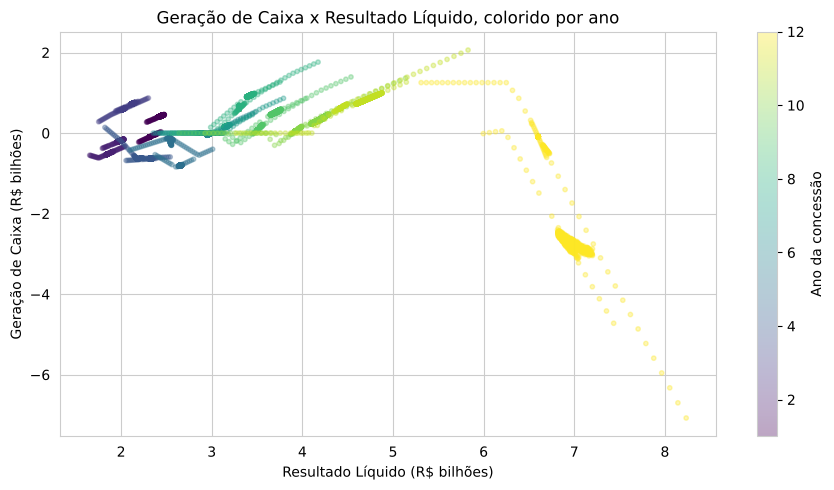

In [4]:
plt.figure()
pts = plt.scatter(df['DRE - Resultado Líquido'] / BI, df['FLU - Geração de Caixa'] / BI,
                  c=df['Ano'], cmap='viridis', alpha=0.35, s=10)
cb = plt.colorbar(pts)
cb.set_label('Ano da concessão')
plt.xlabel('Resultado Líquido (R$ bilhões)')
plt.ylabel('Geração de Caixa (R$ bilhões)')
plt.title('Geração de Caixa x Resultado Líquido, colorido por ano')
plt.tight_layout()
plt.show()

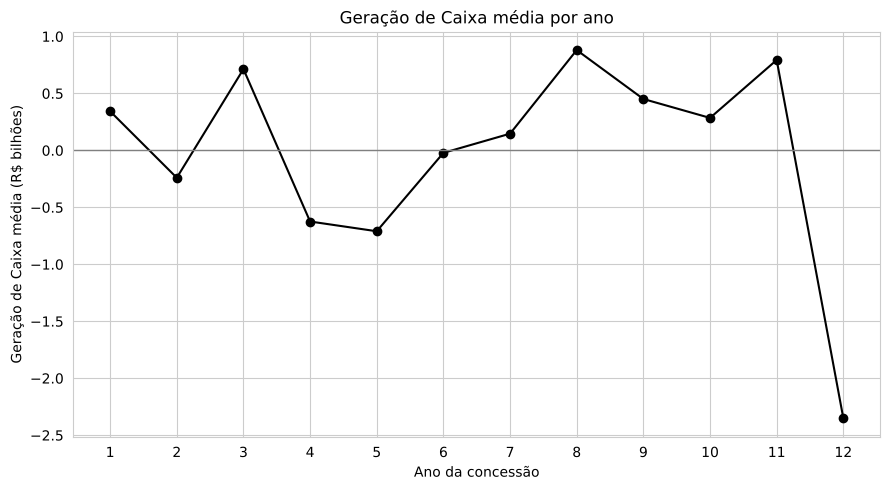

In [5]:
medias = df.groupby('Ano')['FLU - Geração de Caixa'].mean() / BI

plt.figure()
plt.plot(medias.index, medias.values, marker='o', color='black')
plt.axhline(0, color='gray', linewidth=1)
plt.xlabel('Ano da concessão')
plt.ylabel('Geração de Caixa média (R$ bilhões)')
plt.title('Geração de Caixa média por ano')
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

O gráfico de dispersão não mostra uma única reta. Os pontos se organizam em faixas por ano, e a inclinação dentro de cada faixa nem sempre é a mesma. Os pontos de cor mais clara, à direita, são do Ano 12: lá o Resultado Líquido é bem maior (cerca de R$ 6,9 bilhões) e a Geração de Caixa fica fortemente negativa.

O gráfico por ano confirma isso. A Geração de Caixa média oscila bastante de um ano para o outro (positiva nos anos 1, 3, 7, 8, 9, 10 e 11, negativa nos anos 2, 4, 5 e 6) e despenca no Ano 12, em torno de -R$ 2,35 bilhões, que é o ano de encerramento da concessão. Ou seja, não existe uma tendência simples de crescimento ao longo do tempo, e o Ano 12 tem um comportamento bem diferente dos demais. Vamos manter isso em mente nas próximas seções.

## 2. Ajustando o modelo de regressão

Com as variáveis definidas, ajustamos a regressão linear múltipla usando mínimos quadrados ordinários (OLS, do inglês Ordinary Least Squares). Esse método escolhe os coeficientes que deixam a soma dos quadrados dos erros (diferença entre o valor real e o valor que o modelo prevê) a menor possível.

In [6]:
y = df['FLU - Geração de Caixa']
X = df[['DRE - Resultado Líquido', 'Ano']]
X = sm.add_constant(X)

modelo = sm.OLS(y, X).fit()
print(modelo.summary())

                              OLS Regression Results                              
Dep. Variable:     FLU - Geração de Caixa   R-squared:                       0.447
Model:                                OLS   Adj. R-squared:                  0.447
Method:                     Least Squares   F-statistic:                     5814.
Date:                    Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                            20:05:14   Log-Likelihood:            -3.1332e+05
No. Observations:                   14400   AIC:                         6.266e+05
Df Residuals:                       14397   BIC:                         6.267e+05
Df Model:                               2                                         
Covariance Type:                nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------

## 3. Interpretando os coeficientes

Um coeficiente diz quanto a Geração de Caixa muda, em média, quando aquela variável aumenta em uma unidade, mantendo a outra variável fixa. O intercepto é o valor esperado quando todas as variáveis explicativas são zero.

| Coeficiente | Valor | Interpretação |
|---|---|---|
| Intercepto (β₀) | ≈ 1,34 bilhão | geração de caixa esperada quando Resultado Líquido e Ano são zero (não tem leitura prática isolada, serve só para ancorar a reta) |
| Resultado Líquido (β₁) | ≈ -0,93 | mantendo o ano fixo, cada R$ 1 a mais de resultado líquido está associado, em média, a uma queda de R$ 0,93 na geração de caixa |
| Ano (β₂) | ≈ 269 milhões | mantendo o resultado líquido fixo, cada ano adicional de concessão está associado a um aumento médio de R$ 269 milhões na geração de caixa |

O sinal negativo do Resultado Líquido chama atenção, porque a princípio seria de esperar que mais lucro significasse mais caixa gerado. Para entender o que está acontecendo, vale olhar a relação dentro de cada ano separadamente (isso é feito na seção 6). Adiantando o resultado: dentro de cada ano, a relação é positiva na maioria dos anos, e o sinal negativo geral aparece principalmente por causa do Ano 12, em que o Resultado Líquido é muito alto e a Geração de Caixa é muito negativa. Esse tipo de situação, em que a relação com os dados juntos é diferente (ou até oposta) à relação dentro de cada grupo, é conhecido como paradoxo de Simpson.

Então o coeficiente do Resultado Líquido não deve ser lido como "mais lucro reduz o caixa". Ele resume uma mistura de efeitos de anos diferentes, e é muito sensível ao Ano 12.

## 4. Qualidade do ajuste

Duas medidas resumem o quanto o modelo se ajusta aos dados:

- O R² é a proporção da variação da Geração de Caixa que o modelo consegue explicar. Vai de 0 (não explica nada) a 1 (explica tudo).
- O R² ajustado é parecido, mas desconta o efeito de adicionar variáveis ao modelo. Serve para comparar modelos com números diferentes de variáveis.

In [7]:
print(f"R-quadrado:            {modelo.rsquared:.3f}")
print(f"R-quadrado ajustado:   {modelo.rsquared_adj:.3f}")
print(f"Estatistica F:         {modelo.fvalue:.1f}")
print(f"P-valor do teste F:    {modelo.f_pvalue:.2e}")
print(f"Numero de observacoes: {int(modelo.nobs)}")

R-quadrado:            0.447
R-quadrado ajustado:   0.447
Estatistica F:         5814.2
P-valor do teste F:    0.00e+00
Numero de observacoes: 14400


O modelo explica cerca de 45% da variação da Geração de Caixa (R² = 0,447). É um ajuste moderado: nem perto de 1 (o que seria sinal de uma identidade contábil disfarçada, como aconteceria se usássemos EBITDA no lugar de Resultado Líquido) nem perto de zero (o que indicaria que as variáveis escolhidas não têm relação nenhuma com o que queremos prever).

Isso quer dizer que pouco mais da metade da variação na Geração de Caixa fica fora do que o Resultado Líquido e o Ano conseguem explicar. Faz sentido: geração de caixa depende de outros fatores que não estão no modelo, como variação de capital de giro, pagamentos e recebimentos que não coincidem no tempo com o resultado contábil, e comportamentos específicos de cada ano da concessão.

### 4.1 Testes de hipótese sobre o modelo

Dá para olhar a regressão também como um conjunto de testes de hipótese, o mesmo raciocínio das aulas de inferência.

Para cada coeficiente, o teste t compara duas hipóteses:

- H0 (hipótese nula): o coeficiente é zero, ou seja, a variável não ajuda a explicar a Geração de Caixa, com a outra variável fixa
- H1 (hipótese alternativa): o coeficiente é diferente de zero

A estatística t é o coeficiente dividido pelo seu erro-padrão (a incerteza da estimativa). O valor-p é a probabilidade de observar um resultado tão extremo quanto o obtido se H0 fosse verdadeira. Se o valor-p for menor que 0,05, rejeitamos H0. O intervalo de confiança de 95% (IC 95%) é a faixa onde o coeficiente verdadeiro provavelmente está.

Para o modelo como um todo, o teste F usa H0: todos os coeficientes (menos o intercepto) são zero, ou seja, o modelo não explica nada além da média.

In [8]:
alfa = 0.05
tabela_testes = pd.DataFrame({
    'Coeficiente': modelo.params,
    'Erro-padrão': modelo.bse,
    'Estatística t': modelo.tvalues,
    'Valor-p': modelo.pvalues,
    'IC 95% inferior': modelo.conf_int()[0],
    'IC 95% superior': modelo.conf_int()[1],
})
tabela_testes['Decisão (alfa = 0,05)'] = np.where(tabela_testes['Valor-p'] < alfa, 'rejeita H0', 'não rejeita H0')
pd.options.display.float_format = '{:,.4f}'.format
print(tabela_testes.to_string())
pd.reset_option('display.float_format')

print()
print(f"Teste F: estatística = {modelo.fvalue:.1f}, valor-p = {modelo.f_pvalue:.2e}")
print('Decisão:', 'rejeita H0' if modelo.f_pvalue < alfa else 'não rejeita H0')

                               Coeficiente     Erro-padrão  Estatística t  Valor-p    IC 95% inferior    IC 95% superior Decisão (alfa = 0,05)
const                   1,338,013,850.6930 15,871,393.4400        84.3035   0.0000 1,306,903,875.7350 1,369,123,825.6511            rejeita H0
DRE - Resultado Líquido            -0.9278          0.0089      -104.2207   0.0000            -0.9452            -0.9103            rejeita H0
Ano                       268,959,490.4411  3,436,561.2220        78.2641   0.0000   262,223,387.9079   275,695,592.9744            rejeita H0

Teste F: estatística = 5814.2, valor-p = 0.00e+00
Decisão: rejeita H0


Nos dois testes t o valor-p fica praticamente em zero, então rejeitamos H0 para o Resultado Líquido e para o Ano. Os intervalos de confiança de 95% não incluem o zero, o que diz a mesma coisa de outro jeito. O teste F também rejeita H0, então o modelo explica mais do que apenas a média da Geração de Caixa.

Um cuidado: com 14.400 observações, até efeitos pequenos dão valor-p minúsculo. Por isso o valor-p sozinho não basta, e é bom olhar junto o tamanho do efeito e o R². Além disso, os diagnósticos da próxima seção mostram que as premissas do OLS não valem por inteiro, então esses valores-p devem ser lidos como aproximados.

## 5. Diagnósticos do modelo

Além de olhar para o R² e para os coeficientes, é importante verificar se as premissas da regressão linear estão sendo respeitadas. Os resíduos (a diferença entre a Geração de Caixa real e a que o modelo prevê) são a principal ferramenta para isso. Se o modelo estiver bem especificado, os resíduos devem se comportar como ruído: sem padrão, com variância constante, distribuição próxima da normal e independentes entre si. Vamos checar um diagnóstico de cada vez.

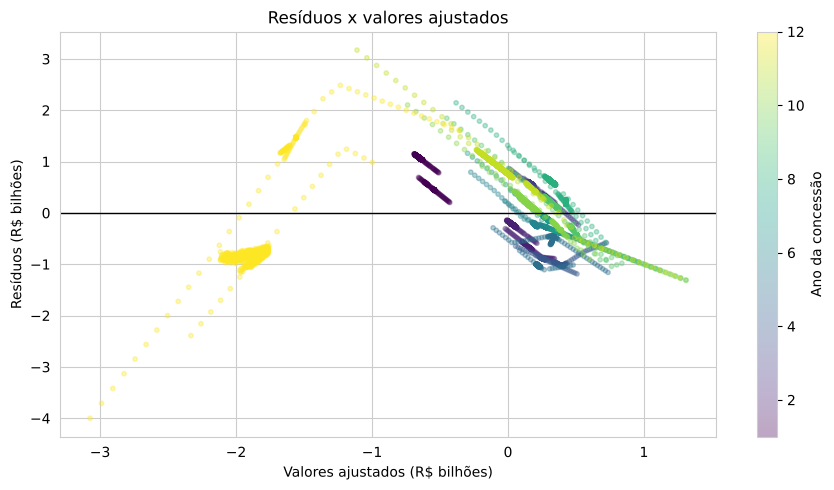

In [9]:
residuos = modelo.resid
ajustados = modelo.fittedvalues

plt.figure()
pts = plt.scatter(ajustados / BI, residuos / BI, c=df['Ano'], cmap='viridis', alpha=0.35, s=10)
cb = plt.colorbar(pts)
cb.set_label('Ano da concessão')
plt.axhline(0, color='black', linewidth=1)
plt.xlabel('Valores ajustados (R$ bilhões)')
plt.ylabel('Resíduos (R$ bilhões)')
plt.title('Resíduos x valores ajustados')
plt.tight_layout()
plt.show()

Esse é o gráfico de resíduos contra valores ajustados (os valores que o modelo prevê). Em um modelo bem especificado, a nuvem ficaria espalhada de forma uniforme ao redor da linha zero, sem padrão. Aqui o padrão é claro: os pontos formam faixas bem separadas, e cada faixa corresponde a um ano. Alguns anos ficam quase todos acima de zero (o modelo prevê menos caixa do que realmente ocorre) e outros quase todos abaixo (o modelo prevê mais do que ocorre). O modelo, com apenas Resultado Líquido e Ano em linha reta, não captura as particularidades de cada ano. Isso indica que a relação não é bem descrita por uma reta única e que a variância dos resíduos muda conforme o valor ajustado.

<Figure size 900x500 with 0 Axes>

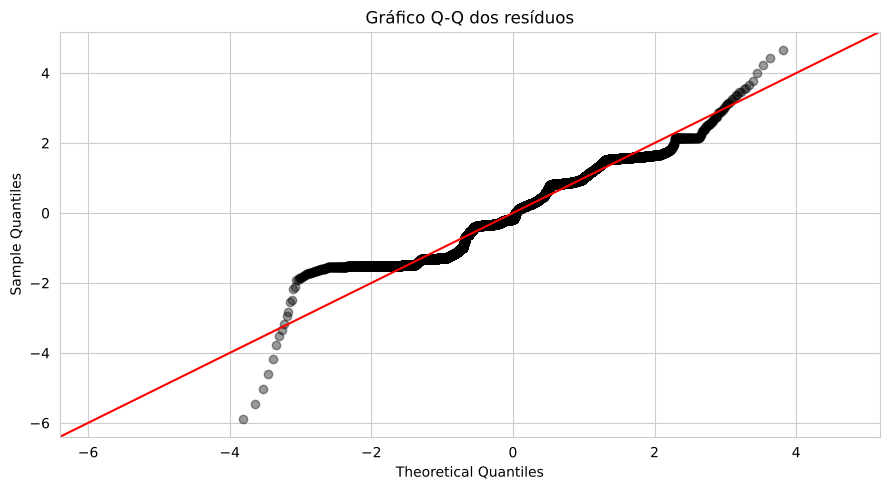

In [10]:
plt.figure()
sm.qqplot(residuos / BI, line='45', fit=True, markerfacecolor='black', markeredgecolor='black', alpha=0.4)
plt.title('Gráfico Q-Q dos resíduos')
plt.tight_layout()
plt.show()

O gráfico Q-Q compara os quantis dos resíduos com os de uma distribuição normal. Se os resíduos fossem normais, os pontos ficariam em cima da linha diagonal. Aqui os pontos formam degraus e se afastam da linha: há um trecho achatado no meio e uma cauda para baixo, à esquerda, com poucos pontos muito negativos (a maioria deles é de cenários do Ano 12). Ou seja, a distribuição dos resíduos não é normal.

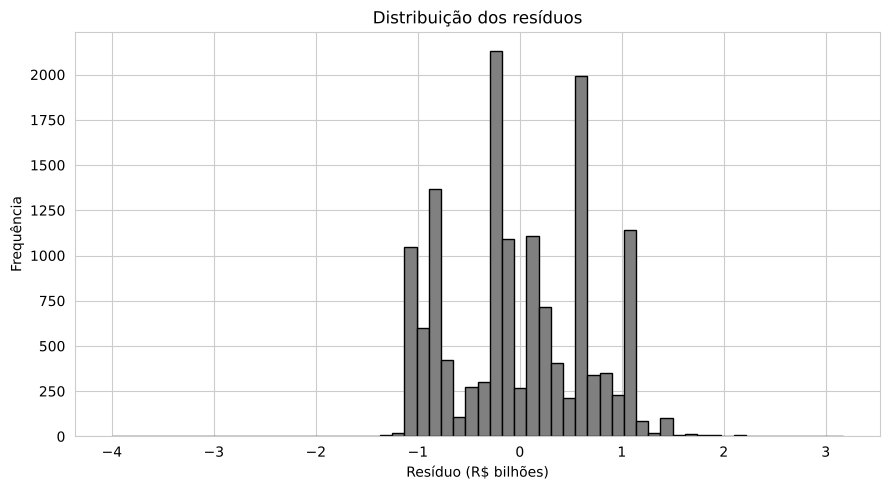

In [11]:
plt.figure()
plt.hist(residuos / BI, bins=60, color='gray', edgecolor='black')
plt.xlabel('Resíduo (R$ bilhões)')
plt.ylabel('Frequência')
plt.title('Distribuição dos resíduos')
plt.tight_layout()
plt.show()

O histograma mostra o mesmo problema de outro ângulo: em vez de um único sino, aparecem vários blocos separados, um para cada grupo de anos, e uma cauda curta à esquerda. Os testes formais abaixo confirmam isso com números.

In [12]:
bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(residuos, X)
shapiro_stat, shapiro_p = stats.shapiro(residuos.sample(5000, random_state=42))

print(f"Teste de Breusch-Pagan (heterocedasticidade): estatistica = {bp_lm:.1f}, p-valor = {bp_p:.2e}")
print(f"Teste de Shapiro-Wilk (normalidade, amostra de 5000): estatistica = {shapiro_stat:.3f}, p-valor = {shapiro_p:.2e}")
print(f"Durbin-Watson (autocorrelacao): {sm.stats.stattools.durbin_watson(residuos):.3f}")

Teste de Breusch-Pagan (heterocedasticidade): estatistica = 2620.0, p-valor = 0.00e+00
Teste de Shapiro-Wilk (normalidade, amostra de 5000): estatistica = 0.961, p-valor = 8.12e-35
Durbin-Watson (autocorrelacao): 0.032


O que cada teste verifica:

- **Breusch-Pagan** testa heterocedasticidade. Homocedasticidade significa que os resíduos têm a mesma variância em todos os níveis do valor ajustado; heterocedasticidade é o contrário. H0: variância constante.
- **Shapiro-Wilk** testa normalidade. H0: os resíduos seguem uma distribuição normal. Aqui foi usada uma amostra de 5.000 resíduos, porque o teste é pensado para amostras desse porte.
- **Durbin-Watson** mede autocorrelação, isto é, o quanto um resíduo se parece com o vizinho. Vai de 0 a 4: perto de 2 significa resíduos independentes, perto de 0 significa autocorrelação positiva forte e perto de 4 significa autocorrelação negativa forte.

Resultados: o Breusch-Pagan rejeita variância constante (p-valor praticamente zero). O Shapiro-Wilk rejeita normalidade. E o Durbin-Watson, bem próximo de zero, indica autocorrelação positiva forte, o que é esperado aqui porque a base está organizada por ano e depois por cenário, então registros vizinhos pertencem ao mesmo ano e se parecem muito.

Nenhum desses resultados impede de usar o modelo, mas eles mostram que os erros-padrão e os valores-p do OLS devem ser interpretados com cautela, porque os testes t e F assumem resíduos independentes e com variância constante.

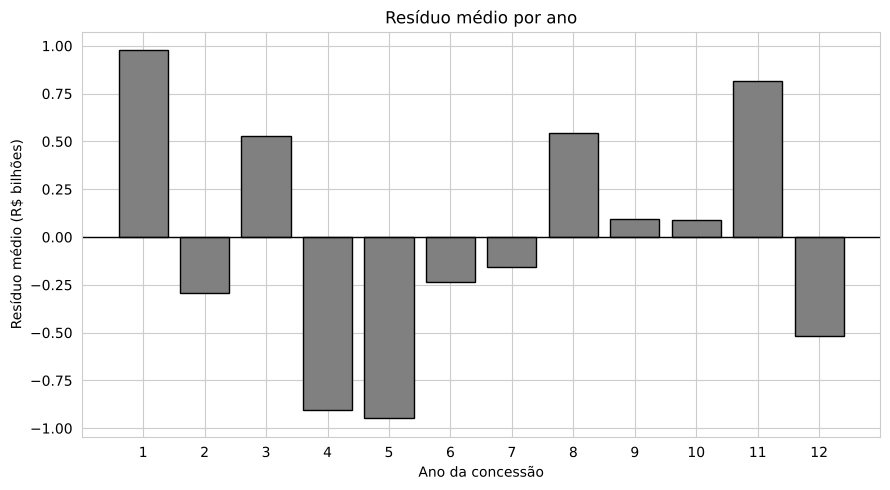

In [13]:
res_ano = (residuos / BI).groupby(df['Ano']).mean()

plt.figure()
plt.bar(res_ano.index, res_ano.values, color='gray', edgecolor='black')
plt.axhline(0, color='black', linewidth=1)
plt.xlabel('Ano da concessão')
plt.ylabel('Resíduo médio (R$ bilhões)')
plt.title('Resíduo médio por ano')
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

Esse gráfico deixa claro o que as faixas mostravam: se os resíduos fossem ruído, a média de cada ano ficaria perto de zero. Em vez disso, ela fica entre +R$ 0,5 bilhão e +R$ 1 bilhão em alguns anos (1, 3, 8 e 11) e perto de -R$ 1 bilhão em outros (4 e 5). Há uma parte sistemática, ligada ao ano, que o modelo não captura.

In [14]:
vif = pd.DataFrame({
    'Variável': X.columns[1:],
    'VIF': [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])]
})
vif

,Variável,VIF
0,DRE - Resultado Líquido,4.366696
1,Ano,4.366696


O VIF (Fator de Inflação da Variância) mede a multicolinearidade, que é quando as variáveis explicativas são muito parecidas entre si e o modelo tem dificuldade para separar o efeito de cada uma. Ele é calculado como 1 / (1 - R²ⱼ), onde R²ⱼ é o R² de prever aquela variável a partir das outras. VIF igual a 1 significa nenhuma colinearidade; acima de 5 já merece atenção; acima de 10 é preocupante.

Aqui o VIF do Resultado Líquido e do Ano fica em torno de 4,4. Está abaixo do limite mais rígido, mas indica colinearidade moderada (o Resultado Líquido também cresce com o Ano, com correlação de cerca de 0,88), o que é mais um motivo para interpretar o coeficiente do Resultado Líquido com cuidado.

## 6. Verificação de sensibilidade: dentro de cada ano e sem o Ano 12

Como o sinal do coeficiente do Resultado Líquido parece estranho, vamos conferir de duas formas. Primeiro, a correlação entre Resultado Líquido e Geração de Caixa dentro de cada ano separadamente.

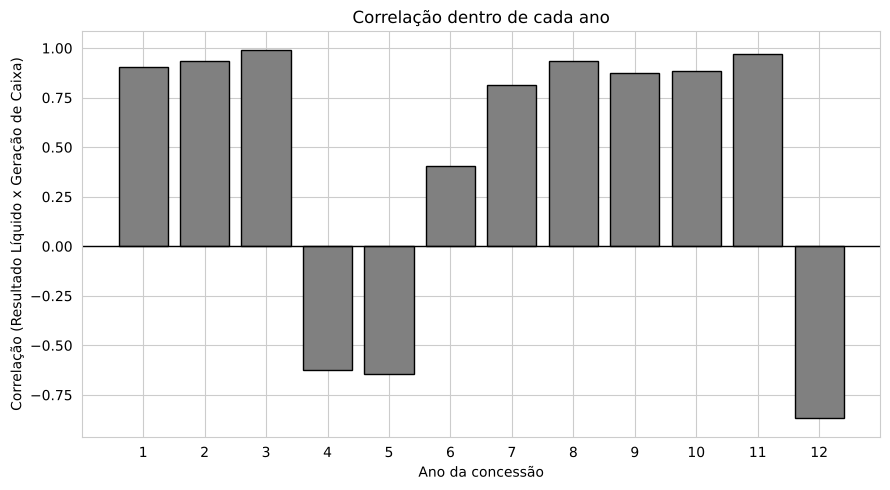

3 anos com correlação negativa: [4, 5, 12]


In [15]:
corr_ano = df.groupby('Ano').apply(
    lambda d: d['DRE - Resultado Líquido'].corr(d['FLU - Geração de Caixa']), include_groups=False)

plt.figure()
plt.bar(corr_ano.index, corr_ano.values, color='gray', edgecolor='black')
plt.axhline(0, color='black', linewidth=1)
plt.xlabel('Ano da concessão')
plt.ylabel('Correlação (Resultado Líquido x Geração de Caixa)')
plt.title('Correlação dentro de cada ano')
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

print((corr_ano < 0).sum(), 'anos com correlação negativa:', list(corr_ano[corr_ano < 0].index))

Dentro de cada ano, a correlação é positiva em 9 dos 12 anos (entre 0,40 e 0,99). Só nos anos 4, 5 e 12 ela é negativa. Então a relação "mais lucro, mais caixa" existe na maior parte do tempo, e o sinal negativo do modelo geral vem da mistura entre anos.

A segunda checagem é ajustar o mesmo modelo sem o Ano 12 e comparar.

In [16]:
df_sem12 = df[df['Ano'] < 12]
y2 = df_sem12['FLU - Geração de Caixa']
X2 = sm.add_constant(df_sem12[['DRE - Resultado Líquido', 'Ano']])
modelo2 = sm.OLS(y2, X2).fit()

comparacao = pd.DataFrame({
    'Com todos os anos': [modelo.params['DRE - Resultado Líquido'], modelo.params['Ano'] / 1e6, modelo.rsquared],
    'Sem o Ano 12': [modelo2.params['DRE - Resultado Líquido'], modelo2.params['Ano'] / 1e6, modelo2.rsquared],
}, index=['Coeficiente do Resultado Líquido', 'Coeficiente do Ano (R$ milhões)', 'R²'])
comparacao.round(3)

,Com todos os anos,Sem o Ano 12
Coeficiente do Resultado Líquido,-0.928,0.730
Coeficiente do Ano (R$ milhões),268.959,-113.075
R²,0.447,0.301


Sem o Ano 12, o coeficiente do Resultado Líquido muda de sinal, de cerca de -0,93 para cerca de +0,73, e o coeficiente do Ano também muda de sinal, de +269 milhões para cerca de -113 milhões. O R² cai de 0,447 para cerca de 0,30. Ou seja, os coeficientes do modelo original dependem muito de um único ano, o de encerramento da concessão, e não são estáveis.

Essa é a principal limitação desta análise, e é um bom exemplo de por que olhar só o R² e o valor-p não basta.

A terceira checagem testa se parte do problema é tratar o Ano como uma reta. Em vez de um número, colocamos o ano como categoria (uma variável indicadora para cada ano), o que dá a cada ano o seu próprio nível de Geração de Caixa. Também comparamos os erros-padrão do modelo original com erros-padrão agrupados por cenário, porque o mesmo cenário aparece nos 12 anos e esses registros não são independentes.

In [17]:
import statsmodels.formula.api as smf

d = df.rename(columns={'DRE - Resultado Líquido': 'R', 'FLU - Geração de Caixa': 'G'})

so_anos = smf.ols('G ~ C(Ano)', d).fit()
com_anos = smf.ols('G ~ R + C(Ano)', d).fit()
com_anos_sem12 = smf.ols('G ~ R + C(Ano)', d[d['Ano'] < 12]).fit()

print(f"R² só com o ano como categoria:              {so_anos.rsquared:.3f}")
print(f"R² com Resultado Líquido + ano como categoria: {com_anos.rsquared:.3f}")
print(f"Coeficiente do Resultado Líquido (todos os anos):  {com_anos.params['R']:.3f}")
print(f"Coeficiente do Resultado Líquido (sem o Ano 12):   {com_anos_sem12.params['R']:.3f}")

cluster = sm.OLS(y, X).fit(cov_type='cluster', cov_kwds={'groups': df['Cenario']})
print()
print('Erro-padrão do Resultado Líquido: padrão =', round(modelo.bse['DRE - Resultado Líquido'], 4),
      '| agrupado por cenário =', round(cluster.bse['DRE - Resultado Líquido'], 4))
print('Erro-padrão do Ano (milhões):     padrão =', round(modelo.bse['Ano'] / 1e6, 2),
      '| agrupado por cenário =', round(cluster.bse['Ano'] / 1e6, 2))

R² só com o ano como categoria:              0.875
R² com Resultado Líquido + ano como categoria: 0.881
Coeficiente do Resultado Líquido (todos os anos):  -0.607
Coeficiente do Resultado Líquido (sem o Ano 12):   0.821



Erro-padrão do Resultado Líquido: padrão = 0.0089 | agrupado por cenário = 0.0101
Erro-padrão do Ano (milhões):     padrão = 3.44 | agrupado por cenário = 2.86


O resultado é bem informativo. Só o ano, como categoria, já explica cerca de 87,5% da variação da Geração de Caixa, contra 44,7% do modelo com o Ano em linha reta. Adicionar o Resultado Líquido eleva o R² para 88,1%, ou seja, ele acrescenta pouco (menos de 1 ponto percentual). Isso mostra que a Geração de Caixa é determinada principalmente pelo ano da concessão, de forma não linear, e não por uma tendência simples.

O coeficiente do Resultado Líquido continua negativo (cerca de -0,61) com todos os anos, e passa a positivo (cerca de +0,82) quando o Ano 12 sai, o que reforça que o sinal negativo vem do Ano 12.

Já os erros-padrão agrupados por cenário ficam muito parecidos com os originais (a diferença é pequena), então a dependência entre os anos de um mesmo cenário não muda as conclusões dos testes.

## 7. Limitações da análise

- **Sensibilidade ao Ano 12**: ao retirar o último ano, os coeficientes do Resultado Líquido e do Ano trocam de sinal e o R² cai de 0,45 para cerca de 0,30. Os coeficientes do modelo completo não devem ser lidos como efeitos estáveis.
- **Pooling de anos e cenários**: o modelo foi ajustado usando os 14.400 registros juntos (12 anos x 1.200 cenários), sem considerar que cada ano tem sua própria dinâmica. Isso é o mesmo tipo de cuidado que já tínhamos identificado na análise descritiva: misturar períodos diferentes pode distorcer a leitura de uma relação, e aqui isso produziu o efeito de Simpson no sinal do Resultado Líquido.
- **Heterocedasticidade e não normalidade dos resíduos**: confirmadas pelos testes de Breusch-Pagan e Shapiro-Wilk. Isso significa que os valores-p e intervalos de confiança do modelo são aproximados, não exatos.
- **Autocorrelação dos resíduos**: o Durbin-Watson próximo de zero e o resíduo médio por ano mostram que os resíduos não são independentes, o que compromete a validade formal dos testes de significância.
- **Variáveis fora do modelo**: só duas variáveis foram usadas (Resultado Líquido e Ano), e o Ano entra como número em linha reta, sem permitir que cada ano tenha seu próprio efeito. Quando o ano entra como categoria, o R² sobe de 0,45 para 0,88, o que mostra que a parte não explicada está ligada principalmente ao ano.
- **Dependência entre registros do mesmo cenário**: cada cenário aparece nos 12 anos, então as observações não são independentes entre si. Os erros-padrão agrupados por cenário mudam pouco, mas o ideal seria um modelo de dados em painel.
- **Relação linear assumida**: o modelo assume uma reta única, e os gráficos mostram que a relação muda de ano para ano.
- **Multicolinearidade moderada**: o VIF em torno de 4,4 mostra que Resultado Líquido e Ano compartilham parte da sua variação, o que dificulta isolar o efeito individual de cada um.

## 8. Conclusão

O modelo de regressão ajustado explica cerca de 45% da variação da Geração de Caixa a partir do Resultado Líquido e do Ano da concessão, um ajuste moderado e estatisticamente significativo, mas longe de perfeito. O coeficiente do Resultado Líquido é negativo (cerca de -0,93), o que contraria a intuição, e a investigação mostrou o motivo: dentro de cada ano a relação entre lucro e caixa é positiva na maioria dos anos, e o sinal negativo geral vem principalmente do Ano 12, em que o Resultado Líquido é muito alto e a Geração de Caixa é muito negativa. Sem o Ano 12, os dois coeficientes mudam de sinal e o R² cai para cerca de 0,30.

Os diagnósticos mostraram que o modelo não respeita as premissas clássicas da regressão linear: os resíduos se organizam por ano, não têm variância constante, não são normais e são autocorrelacionados. Ainda assim, o exercício cumpriu o papel desta entrega: explorar uma relação real entre variáveis financeiras, evitando o erro de montar um modelo tautológico a partir de variáveis quase idênticas, e registrando as limitações que qualquer leitura dos coeficientes precisa levar em conta. Para a Geração de Caixa, o ano da concessão importa mais do que uma tendência linear simples consegue representar: só o ano, tratado como categoria, explica cerca de 87,5% da variação, e o Resultado Líquido acrescenta menos de 1 ponto percentual a isso.

## Glossário dos termos utilizados

| Termo | O que significa |
|---|---|
| Regressão linear múltipla | Modelo que descreve uma variável (a dependente) como uma soma ponderada de outras variáveis (as explicativas) mais um erro |
| OLS (mínimos quadrados ordinários) | Método que escolhe os coeficientes minimizando a soma dos quadrados dos resíduos |
| Variável dependente / explicativa | A dependente é a que se quer explicar (Geração de Caixa); as explicativas são as usadas para explicá-la (Resultado Líquido e Ano) |
| Coeficiente | Quanto a variável dependente muda, em média, quando a explicativa sobe uma unidade, mantendo as demais fixas |
| Intercepto | Valor esperado da variável dependente quando todas as explicativas são zero |
| Resíduo | Diferença entre o valor real e o valor previsto pelo modelo |
| Valor ajustado | Valor que o modelo prevê para cada observação |
| Correlação de Pearson | Medida de relação linear entre duas variáveis, de -1 a +1 |
| R² | Proporção da variação da variável dependente explicada pelo modelo (0 a 1) |
| R² ajustado | R² com desconto pelo número de variáveis do modelo |
| Erro-padrão | Medida da incerteza da estimativa de um coeficiente |
| Estatística t | Coeficiente dividido pelo erro-padrão; mede quão longe de zero ele está |
| H0 e H1 | Hipótese nula (não há efeito) e hipótese alternativa (há efeito) |
| Valor-p | Probabilidade de obter um resultado tão extremo quanto o observado se H0 fosse verdadeira |
| Intervalo de confiança (IC 95%) | Faixa de valores plausíveis para o coeficiente verdadeiro |
| Teste F | Testa se o modelo, como um todo, explica algo além da média |
| Multicolinearidade | Quando as variáveis explicativas são muito parecidas entre si |
| VIF | Fator de Inflação da Variância, mede a multicolinearidade: 1 é nenhuma, acima de 5 atenção, acima de 10 preocupante |
| Homocedasticidade / heterocedasticidade | Variância dos resíduos constante / não constante |
| Breusch-Pagan | Teste de heterocedasticidade (H0: variância constante) |
| Normalidade | Quando os resíduos seguem uma distribuição normal (formato de sino) |
| Shapiro-Wilk | Teste de normalidade (H0: resíduos normais) |
| Gráfico Q-Q | Compara os quantis dos resíduos com os de uma normal; pontos sobre a diagonal indicam normalidade |
| Autocorrelação | Quando resíduos de observações vizinhas se parecem entre si |
| Durbin-Watson | Mede a autocorrelação: perto de 2 é independência, perto de 0 é autocorrelação positiva forte |
| Pooling | Juntar todos os períodos e grupos em uma única regressão |
| Paradoxo de Simpson | Quando a relação com os dados juntos é diferente (ou oposta) à relação dentro de cada grupo |
| Variável categórica (indicadora) | Variável que representa grupos (aqui, cada ano), com um coeficiente próprio para cada grupo |
| Erro-padrão agrupado (cluster) | Erro-padrão que considera que observações do mesmo grupo (aqui, o mesmo cenário em anos diferentes) são dependentes |
| Sensibilidade | Verificar o quanto os resultados mudam ao alterar a amostra ou o modelo |